# Mecânica dos Fluidos

## Aula — A Equação de Poisson: do fenômeno físico ao modelo matemático

### Modelagem matemática e simulação computacional

A **equação de Poisson** aparece em diversos problemas da física e da engenharia.

Embora fenômenos como condução de calor, difusão de uma substância, eletrostática e escoamento de fluidos sejam fisicamente diferentes, muitos deles conduzem à mesma estrutura matemática:

$$
-\nabla\cdot(k\nabla u)=f.
$$

Quando $k$ é constante, essa equação pode ser escrita como

$$
-\Delta u = \frac{f}{k},
$$

onde

$$
\Delta u = \nabla\cdot(\nabla u)
$$

é o **operador Laplaciano**.

Neste notebook, nosso objetivo não será começar pela equação diferencial.

Faremos o caminho contrário:

> **fenômeno físico → princípio de conservação → lei constitutiva → equação diferencial**

A ideia central é compreender **de onde vem a equação que posteriormente será resolvida computacionalmente**.

### Objetivos

Ao final deste notebook, devemos ser capazes de:

- identificar um **princípio de conservação** em um problema físico;
- distinguir uma lei de conservação de uma **lei constitutiva**;
- compreender o significado físico de um **fluxo**;
- derivar a equação de Poisson a partir de um balanço local;
- interpretar fisicamente as condições de contorno;
- resolver analiticamente um problema simples em uma dimensão;
- visualizar a solução utilizando Python;
- reconhecer a mesma estrutura matemática em diferentes fenômenos físicos;
- compreender a relação entre **integração por partes em 1D** e o **Teorema da Divergência** em dimensões superiores.

> **Ideia central**
>
> A equação de Poisson não é uma equação introduzida pelo método dos elementos finitos.
>
> Ela surge da **modelagem do fenômeno físico**. O método dos elementos finitos será apenas uma das ferramentas que utilizaremos posteriormente para resolvê-la.

## 1. Do fenômeno físico ao modelo matemático

Na Mecânica do Contínuo, um corpo ou fluido é tratado como um meio contínuo.

Em vez de acompanhar individualmente moléculas ou partículas, descrevemos grandezas físicas por meio de **campos** definidos sobre uma região do espaço.

Alguns exemplos são:

- temperatura $T(\mathbf{x},t)$;
- densidade $\rho(\mathbf{x},t)$;
- velocidade $\mathbf{v}(\mathbf{x},t)$;
- pressão $p(\mathbf{x},t)$;
- concentração $c(\mathbf{x},t)$.

A construção de um modelo matemático para esses campos normalmente envolve três ingredientes fundamentais:

1. **princípios de conservação ou balanço**;
2. **leis constitutivas**;
3. **condições iniciais e de contorno**.

Essa organização é característica da Mecânica do Contínuo e será utilizada ao longo da disciplina.

> **Referências de organização**
>
> - M. E. Gurtin, *An Introduction to Continuum Mechanics*, (1981).
> - P. T. R. Mendonça e E. A. Fancello, *O Método de Elementos Finitos Aplicado à Mecânica dos Sólidos* (2019).

## 2. Um princípio de balanço

Considere inicialmente uma região unidimensional muito simples:

$$
[a,b].
$$

Imagine que uma determinada grandeza física esteja sendo transportada através desse intervalo.

Ela pode representar, por exemplo:

- energia térmica;
- massa de uma substância;
- quantidade de movimento.

Denotaremos por $q(x)$ o **fluxo** dessa grandeza.

A ideia fundamental de um balanço pode ser expressa esquematicamente como

$$
\boxed{
\text{acumulação}
=
\text{entrada}
-
\text{saída}
+
\text{produção}.
}
$$

Essa relação aparentemente simples será o ponto de partida para a obtenção de várias equações diferenciais utilizadas em Mecânica dos Fluidos.

### 2.1 Balanço em um intervalo

Considere uma região unidimensional

$$
\Omega=[a,b].
$$

Vamos imaginar que uma determinada grandeza física seja transportada através desse intervalo.

Adotaremos como sentido positivo o sentido crescente do eixo $x$:

$$
a \qquad \longrightarrow \qquad b.
$$

Seja $q(x)$ o **fluxo** da grandeza transportada.

Além disso, suponha que exista uma *fonte distribuída* $f(x)$ no interior do intervalo.

Durante o *regime estacionário* não ocorre acumulação. Portanto,

$$
\text{entrada}
-
\text{saída}
+
\text{produção interna}
=
0.
$$

Aplicando esse balanço ao intervalo $[a,b]$, obtemos

$$
q(a)-q(b)+\int_a^b f(x)\,dx=0.
$$

Ou, equivalentemente,

$$
q(b)-q(a)=\int_a^b f(x)\,dx.
$$

Essa é uma **forma integral do princípio de balanço**.

> **Interpretação física**
>
> A diferença entre o fluxo que sai e o fluxo que entra deve ser compensada
> pela quantidade produzida no interior do domínio.

### 2.2 Do balanço integral ao balanço local

Pelo Teorema Fundamental do Cálculo,

$$
q(b)-q(a)
=
\int_a^b \frac{dq}{dx}\,dx.
$$

Substituindo no balanço,

$$
\int_a^b \frac{dq}{dx}\,dx
=
\int_a^b f(x)\,dx.
$$

Portanto,

$$
\int_a^b
\left(
\frac{dq}{dx}-f
\right)dx
=
0.
$$

Como o intervalo $[a,b]$ é arbitrário, concluímos que

$$
\boxed{
\frac{dq}{dx}=f.
}
$$

Essa é a **forma local do balanço**.

Observe a passagem:

$$
\boxed{
\text{balanço integral}
\quad\longrightarrow\quad
\text{equação diferencial local}.
}
$$

Até este ponto, não especificamos qual grandeza física está sendo transportada.

A equação expressa apenas um **princípio de balanço**.

## 3. Do balanço à equação de Poisson

O princípio de balanço, sozinho, não é suficiente para determinar o campo desconhecido.

Precisamos de uma relação adicional que descreva como o material responde ao fenômeno considerado.

Essa relação é denominada **lei constitutiva**.

Um grande número de *fenômenos de transporte* pode ser descrito por uma relação da forma

$$
\boxed{
q=-k\frac{du}{dx},
}
$$

onde:

- $u(x)$ é o campo que desejamos determinar;
- $q(x)$ é o fluxo;
- $k$ é uma propriedade do meio.

O sinal negativo possui significado físico importante:

> o transporte ocorre no sentido em que $u$ diminui.

Por exemplo, no caso da condução de calor, o calor flui espontaneamente das regiões de maior temperatura para as regiões de menor temperatura.

### 3.1 Balanço + lei constitutiva

Obtivemos, a partir do princípio de balanço,

$$
\frac{dq}{dx}=f.
$$

A lei constitutiva fornece

$$
q=-k\frac{du}{dx}.
$$

Substituindo a lei constitutiva no balanço,

$$
\frac{d}{dx}
\left(
-k\frac{du}{dx}
\right)
=
f.
$$

Portanto,

$$
\boxed{
-\frac{d}{dx}
\left(
k\frac{du}{dx}
\right)
=
f.
}
$$

Essa é a forma unidimensional de uma importante classe de problemas de Poisson.

Se $k$ for constante,

$$
\boxed{
-k\frac{d^2u}{dx^2}=f.
}
$$

ou

$$
\boxed{
-\frac{d^2u}{dx^2}
=
\frac{f}{k}.
}
$$

> ### O que aprendemos até aqui?
>
> A equação de Poisson não foi postulada.
>
> Ela surgiu da combinação de dois ingredientes:
>
> $$
> \boxed{
> \text{princípio de balanço}
> +
> \text{lei constitutiva}
> =
> \text{equação de campo}.
> }
> $$
>
> O **balanço** expressa uma lei física geral.
>
> A **lei constitutiva** introduz as propriedades específicas do meio.
>
> Essa distinção será fundamental quando estudarmos Mecânica dos Fluidos.

## 4. A mesma estrutura em diferentes fenômenos

Obtivemos a estrutura

$$
-\frac{d}{dx}
\left(
k\frac{du}{dx}
\right)
=
f.
$$

Essa equação não pertence exclusivamente a um determinado fenômeno físico.

O significado de $u$, do fluxo $q$, do coeficiente $k$ e da fonte $f$
depende do problema considerado.

Essa é uma característica importante da modelagem matemática:

> **fenômenos fisicamente diferentes podem compartilhar a mesma estrutura matemática.**

Vamos examinar alguns exemplos.

### 4.1 Condução de calor

Considere uma barra na qual a temperatura é descrita pelo campo

$$
T=T(x).
$$

A lei constitutiva para a condução de calor é a **Lei de Fourier**:

$$
\boxed{
q=-k\frac{dT}{dx},
}
$$

onde:

- $q$ é o fluxo de calor;
- $k$ é a condutividade térmica;
- $T$ é a temperatura.

O sinal negativo indica que o calor flui no sentido de diminuição da temperatura.

Se existe uma "fonte volumétrica" de calor $f(x)$, o balanço estacionário fornece

$$
\frac{dq}{dx}=f.
$$

Substituindo a Lei de Fourier,

$$
-\frac{d}{dx}
\left(
k\frac{dT}{dx}
\right)
=
f.
$$

Para $k$ constante,

$$
\boxed{
-k\frac{d^2T}{dx^2}=f.
}
$$

Portanto, a distribuição estacionária de temperatura é governada por uma
equação de Poisson.

> **Observe**
>
> A Lei de Fourier não é um princípio de conservação.
>
> O balanço de energia e a Lei de Fourier desempenham papéis diferentes:
>
> $$
> \boxed{
> \text{balanço de energia}
> +
> \text{Lei de Fourier}
> \longrightarrow
> \text{equação de Poisson}.
> }
> $$

### 4.2 Difusão de uma substância

Considere agora a concentração de uma substância

$$
c=c(x).
$$

A **Lei de Fick** estabelece que o fluxo difusivo é proporcional ao gradiente
de concentração:

$$
\boxed{
J=-D\frac{dc}{dx},
}
$$

onde $D$ é o coeficiente de difusão.

Novamente, o sinal negativo indica transporte das regiões de maior
concentração para as regiões de menor concentração.

Em regime estacionário, considerando uma fonte distribuída $s(x)$,

$$
\frac{dJ}{dx}=s.
$$

Substituindo a Lei de Fick,

$$
-\frac{d}{dx}
\left(
D\frac{dc}{dx}
\right)
=
s.
$$

Se $D$ for constante,

$$
\boxed{
-D\frac{d^2c}{dx^2}=s.
}
$$

Mais uma vez encontramos a equação de Poisson.

| Fenômeno | Campo desconhecido | Lei constitutiva |
|---|---|---|
| Condução de calor | $T$ | $q=-kT'$ |
| Difusão | $c$ | $J=-Dc'$ |

### 4.3 Eletrostática

Na eletrostática, o campo elétrico $\mathbf{E}$ pode ser escrito em termos
do potencial elétrico $\phi$:

$$
\mathbf{E}=-\nabla\phi.
$$

A Lei de Gauss, na forma diferencial, estabelece

$$
\nabla\cdot\mathbf{E}
=
\frac{\rho}{\varepsilon},
$$

onde $\rho$ é a densidade de carga elétrica e $\varepsilon$ é a
permissividade do meio.

Substituindo

$$
\mathbf{E}=-\nabla\phi,
$$

obtemos

$$
-\nabla\cdot(\nabla\phi)
=
\frac{\rho}{\varepsilon}.
$$

Como

$$
\Delta\phi=\nabla\cdot(\nabla\phi),
$$

segue que

$$
\boxed{
-\Delta\phi
=
\frac{\rho}{\varepsilon}.
}
$$

Novamente encontramos a equação de Poisson.

## 5. A equação de Poisson na Mecânica dos Fluidos

Considere o escoamento de um fluido viscoso entre duas placas planas,
paralelas e estacionárias.

Vamos admitir que:

- o fluido seja Newtoniano;
- o escoamento seja incompressível;
- o regime seja estacionário;
- as placas sejam suficientemente longas;
- o escoamento seja totalmente desenvolvido;
- a velocidade possua apenas uma componente.

Escolhendo $x$ na direção do escoamento e $y$ na direção transversal,

$$
\mathbf{v}=u(y)\mathbf{e}_x.
$$

Nosso objetivo será determinar o perfil de velocidade

$$
u=u(y).
$$

### 5.1 Hipóteses do modelo

Para construir um modelo matemático simples do escoamento entre duas placas
paralelas, adotaremos algumas hipóteses.

Essas hipóteses não são apenas simplificações matemáticas: elas definem
o fenômeno físico que estamos modelando.

#### Fluido Newtoniano

Admitiremos que o fluido seja **Newtoniano**.

Isso significa que a tensão de cisalhamento é proporcional à taxa de
deformação do fluido. Para o escoamento que estudaremos,

$$
\tau_{xy}
=
\mu\frac{du}{dy},
$$

onde $\mu$ é a **viscosidade dinâmica**.

Essa relação constitui uma **lei constitutiva** e será fundamental para
relacionar o balanço de quantidade de movimento ao campo de velocidades.

---

#### Fluido incompressível

Admitiremos que o fluido seja **incompressível**, isto é, que sua densidade
permaneça constante:

$$
\rho=\text{constante}.
$$

Para um escoamento incompressível, a conservação de massa pode ser escrita
como

$$
\nabla\cdot\mathbf{v}=0.
$$

No problema considerado, veremos que essa condição será automaticamente
satisfeita pelas hipóteses adotadas para o campo de velocidades.

---

#### Regime estacionário

Admitiremos que o escoamento esteja em **regime estacionário**.

Isso significa que, em cada ponto do domínio, as grandezas do escoamento
não variam com o tempo.

Em particular,

$$
\frac{\partial\mathbf{v}}{\partial t}=0.
$$

Isso não significa que o fluido esteja parado.

As partículas continuam se movimentando; o que não muda com o tempo é o
campo de velocidades observado em cada posição.

---

#### Placas suficientemente longas

Consideraremos duas placas paralelas suficientemente longas para que
possamos estudar uma região afastada da entrada e da saída do canal.

Próximo à entrada, o perfil de velocidade ainda está se desenvolvendo.

Longe dessa região, os efeitos de entrada podem ser desprezados e o
escoamento pode ser considerado **totalmente desenvolvido**.

---

#### Escoamento totalmente desenvolvido

Dizer que o escoamento é totalmente desenvolvido significa que o perfil
de velocidade não muda ao longo da direção do escoamento.

Escolhendo $x$ na direção das placas,

$$
\frac{\partial u}{\partial x}=0.
$$

Assim, a velocidade pode variar transversalmente ao canal, mas seu perfil
permanece o mesmo à medida que avançamos na direção $x$.

---

#### Velocidade com apenas uma componente

Admitiremos que o movimento ocorra apenas na direção $x$.

Portanto,

$$
\mathbf{v}
=
u\,\mathbf{e}_x.
$$

Como o escoamento é também totalmente desenvolvido,

$$
u=u(y),
$$

e finalmente podemos escrever

$$
\boxed{
\mathbf{v}(x,y)
=
u(y)\mathbf{e}_x.
}
$$

Observe uma distinção importante:

$$
\boxed{
\text{direção do movimento}
\neq
\text{direção de variação da velocidade}.
}
$$

O fluido se movimenta na direção $x$, mas a magnitude de sua velocidade
varia na direção $y$.

> ### O que nossas hipóteses fizeram?
>
> Partimos de um campo de velocidades que, em geral, poderia depender
> da posição e do tempo,
>
> $$
> \mathbf{v}=\mathbf{v}(x,y,z,t),
> $$
>
> e chegamos ao campo muito mais simples
>
> $$
> \boxed{
> \mathbf{v}=u(y)\mathbf{e}_x.
> }
> $$
>
> Essa redução não foi uma manipulação matemática arbitrária.
> Ela resultou das **hipóteses físicas adotadas para o problema**.

### 5.2 Balanço de quantidade de movimento

Para determinar o campo de velocidades, precisamos aplicar um dos princípios
fundamentais da Mecânica: o **balanço de quantidade de movimento**.

Considere um pequeno elemento retangular de fluido, de dimensões

$$
dx\times dy,
$$

e espessura unitária na direção perpendicular ao plano.

Vamos analisar as forças que atuam sobre esse elemento na direção $x$.

Para o problema considerado, teremos duas contribuições principais:

- forças de **pressão**, atuando nas faces verticais;
- forças **viscosas de cisalhamento**, atuando nas faces horizontais.

Nosso objetivo será aplicar a Segunda Lei de Newton a esse elemento.

#### Forças de pressão

A pressão atua sempre na direção normal à superfície.

Na face esquerda do elemento, localizada em $x$, a força de pressão atua
na direção positiva de $x$.

Como a área da face é $dy$ para espessura unitária,

$$
F_{p,\mathrm{esq}}
=
p(x)\,dy.
$$

Na face direita, localizada em $x+dx$, a pressão atua na direção negativa
de $x$:

$$
F_{p,\mathrm{dir}}
=
-p(x+dx)\,dy.
$$

A resultante das forças de pressão é, portanto,

$$
F_p
=
\left[
p(x)-p(x+dx)
\right]dy.
$$

Como $dx$ é pequeno, podemos aproximar a pressão na face direita por

$$
p(x+dx)
\approx
p(x)
+
\frac{\partial p}{\partial x}dx.
$$

Substituindo,

$$
F_p
=
\left[
p(x)
-
p(x)
-
\frac{\partial p}{\partial x}dx
\right]dy.
$$

Portanto,

$$
\boxed{
F_p
=
-\frac{\partial p}{\partial x}\,dx\,dy.
}
$$

Assim, por unidade de volume, a contribuição da pressão para a força na
direção $x$ é

$$
\boxed{
-\frac{\partial p}{\partial x}.
}
$$

> **Interpretação**
>
> Se a pressão diminui na direção do escoamento,
>
> $$
> \frac{\partial p}{\partial x}<0,
> $$
>
> então
>
> $$
> -\frac{\partial p}{\partial x}>0.
> $$
>
> Portanto, o gradiente de pressão produz uma força na direção positiva
> de $x$.

#### Forças viscosas

As camadas vizinhas do fluido também exercem forças tangenciais sobre
o elemento.

Denotaremos por

$$
\tau_{xy}
$$

a tensão de cisalhamento associada à força na direção $x$ atuando sobre
uma superfície cuja normal está associada à direção $y$.

Na face superior,

$$
F_{\tau,\mathrm{sup}}
=
\tau_{xy}(y+dy)\,dx.
$$

Na face inferior, a contribuição possui sentido oposto:

$$
F_{\tau,\mathrm{inf}}
=
-\tau_{xy}(y)\,dx.
$$

Assim,

$$
F_\tau
=
\left[
\tau_{xy}(y+dy)-\tau_{xy}(y)
\right]dx.
$$

Como $dy$ é pequeno,

$$
\tau_{xy}(y+dy)
\approx
\tau_{xy}(y)
+
\frac{\partial\tau_{xy}}{\partial y}dy.
$$

Logo,

$$
\boxed{
F_\tau
=
\frac{\partial\tau_{xy}}{\partial y}
\,dx\,dy.
}
$$

### 5.3 Balanço das forças

Aplicamos agora a Segunda Lei de Newton na direção $x$:

$$
\sum F_x = m a_x.
$$

Para o campo de velocidades considerado,

$$
\mathbf{v}=u(y)\mathbf{e}_x,
$$

o escoamento é estacionário e totalmente desenvolvido.

A aceleração material é

$$
\mathbf{a}
=
\frac{\partial\mathbf{v}}{\partial t}
+
(\mathbf{v}\cdot\nabla)\mathbf{v}.
$$

A primeira parcela é nula porque o escoamento é estacionário. A segunda
também é nula porque $u$ não varia na direção $x$.

Portanto,

$$
\mathbf{a}=0.
$$

Assim, na direção $x$,

$$
\sum F_x=0.
$$

Portanto,

$$
F_p+F_\tau=0.
$$

Substituindo as expressões obtidas,

$$
-\frac{\partial p}{\partial x}\,dx\,dy
+
\frac{\partial\tau_{xy}}{\partial y}\,dx\,dy
=
0.
$$

Dividindo por $dx\,dy$,

$$
\boxed{
-\frac{\partial p}{\partial x}
+
\frac{\partial\tau_{xy}}{\partial y}
=
0.
}
$$

Essa é a forma local do **balanço de quantidade de movimento na direção $x$**
para o problema considerado.

> ### Balanço não é lei constitutiva
>
> Até este momento utilizamos apenas o **balanço de quantidade de movimento**:
>
> $$
> -\frac{\partial p}{\partial x}
> +
> \frac{\partial\tau_{xy}}{\partial y}
> =
> 0.
> $$
>
> Essa equação ainda envolve duas grandezas desconhecidas:
>
> $$
> p
> \qquad\text{e}\qquad
> \tau_{xy}.
> $$
>
> Precisamos agora caracterizar **como o fluido responde à deformação**.
>
> É nesse momento que entra a **lei constitutiva**.

### 5.3 A lei constitutiva

Para um fluido Newtoniano,

$$
\boxed{
\tau_{xy}
=
\mu\frac{du}{dy},
}
$$

onde $\mu$ é a viscosidade dinâmica.

Substituindo essa relação no balanço de quantidade de movimento,

$$
-\frac{dp}{dx}
+
\frac{d}{dy}
\left(
\mu\frac{du}{dy}
\right)
=
0.
$$

Portanto,

$$
-\frac{d}{dy}
\left(
\mu\frac{du}{dy}
\right)
=
-\frac{dp}{dx}.
$$

Para viscosidade constante,

$$
\boxed{
-\mu\frac{d^2u}{dy^2}
=
-\frac{dp}{dx}.
}
$$

Dividindo por $\mu$,

$$
\boxed{
-\frac{d^2u}{dy^2}
=
-\frac{1}{\mu}\frac{dp}{dx}.
}
$$

Temos novamente uma **equação de Poisson**.

> ### O que mudou?
>
> Matematicamente, quase nada.
>
> Antes tínhamos
>
> $$
> -\frac{d}{dx}
> \left(
> k\frac{du}{dx}
> \right)
> =
> f.
> $$
>
> Agora temos
>
> $$
> -\frac{d}{dy}
> \left(
> \mu\frac{du}{dy}
> \right)
> =
> -\frac{dp}{dx}.
> $$
>
> O significado físico, entretanto, é completamente diferente.
>
> Agora:
>
> - $u$ é a **velocidade do fluido**;
> - $\mu$ representa a **viscosidade**;
> - $-dp/dx$ é a ação que impulsiona o escoamento.
>
> A estrutura matemática permanece essencialmente a mesma.

### 5.4 Geometria e condições de contorno

Considere duas placas planas, paralelas e estacionárias, separadas por uma
distância $2h$.

Escolhemos:

- $x$ na direção do escoamento;
- $y$ na direção transversal;
- $y=0$ no plano médio entre as placas.

As placas estão localizadas em

$$
y=-h
\qquad\text{e}\qquad
y=h.
$$

Para o escoamento totalmente desenvolvido,

$$
\mathbf{v}=u(y)\mathbf{e}_x.
$$

Portanto, embora o fluido se mova na direção $x$, seu perfil de velocidade
varia apenas na direção $y$.

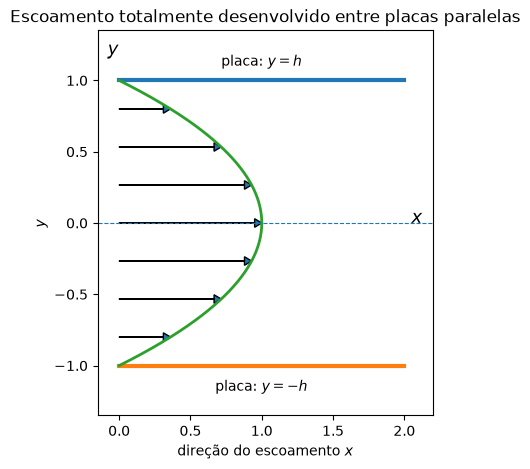

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Geometria
h = 1.0

# Coordenada transversal
y = np.linspace(-h, h, 300)

# Perfil parabólico adimensional
u = 1 - (y / h)**2

fig, ax = plt.subplots(figsize=(9, 5))

# Placas
ax.plot([0, 2.0], [ h,  h], linewidth=3)
ax.plot([0, 2.0], [-h, -h], linewidth=3)

# Perfil de velocidade
ax.plot(u, y, linewidth=2)

# Algumas setas representando a velocidade
for yi in np.linspace(-0.8*h, 0.8*h, 7):
    ui = 1 - (yi/h)**2
    ax.arrow(
        0, yi, ui, 0,
        head_width=0.06,
        head_length=0.05,
        length_includes_head=True
    )

# Linha central
ax.axhline(0, linewidth=0.8, linestyle="--")

# Identificação das placas
ax.text(1.0,  h + 0.10, r"placa: $y=h$", ha="center")
ax.text(1.0, -h - 0.18, r"placa: $y=-h$", ha="center")

# Eixos
ax.text(2.05, 0, r"$x$", fontsize=13)
ax.text(-0.08, h + 0.18, r"$y$", fontsize=13)

ax.set_xlim(-0.15, 2.2)
ax.set_ylim(-1.35*h, 1.35*h)
ax.set_aspect("equal")

ax.set_xlabel(r"direção do escoamento $x$")
ax.set_ylabel(r"$y$")

ax.set_title("Escoamento totalmente desenvolvido entre placas paralelas")

plt.show()

### 5.5 Condição de não deslizamento

Para um fluido viscoso em contato com uma parede sólida estacionária,
adotaremos a **condição de não deslizamento** (*no-slip condition*).

A velocidade do fluido junto à parede é igual à velocidade da própria parede.

Como as duas placas estão estacionárias,

$$
u(-h)=0,
$$

e

$$
u(h)=0.
$$

Portanto,

$$
\boxed{
u(-h)=u(h)=0.
}
$$

Essas são as **condições de contorno de Dirichlet** do nosso problema.

### 5.6 O problema de valor de contorno

Obtivemos a equação

$$
-\mu\frac{d^2u}{dy^2}
=
-\frac{dp}{dx}.
$$

Para simplificar a notação, definimos

$$
G=-\frac{dp}{dx}.
$$

Em um escoamento impulsionado por uma queda de pressão,

$$
G>0.
$$

O problema pode então ser escrito como

$$
\boxed{
-\mu u''(y)=G,
\qquad -h<y<h,
}
$$

sujeito às condições de contorno

$$
\boxed{
u(-h)=u(h)=0.
}
$$

Agora temos um **problema de valor de contorno completo**:

1. uma equação diferencial no domínio;
2. condições de contorno na fronteira.

> ### Do fenômeno ao problema matemático
>
> Percorremos o caminho
>
> $$
> \boxed{
> \begin{array}{c}
> \text{escoamento viscoso}\\
> \downarrow\\
> \text{balanço de quantidade de movimento}\\
> \downarrow\\
> \text{lei constitutiva Newtoniana}\\
> \downarrow\\
> \text{equação de Poisson}\\
> \downarrow\\
> \text{condições de não deslizamento}\\
> \downarrow\\
> \text{problema de valor de contorno}
> \end{array}
> }
> $$
>
> Somente agora estamos prontos para resolver o problema.

## 6. Solução analítica

Nosso problema é

$$
-\mu u''(y)=G,
\qquad -h<y<h,
$$

com

$$
u(-h)=u(h)=0.
$$

Dividindo por $-\mu$,

$$
u''(y)=-\frac{G}{\mu}.
$$

Integrando uma vez em relação a $y$,

$$
u'(y)
=
-\frac{G}{\mu}y+C_1.
$$

Integrando novamente,

$$
u(y)
=
-\frac{G}{2\mu}y^2+C_1y+C_2.
$$

Aplicamos agora as condições de contorno.

### 6.1 Aplicação das condições de contorno

Em $y=h$,

$$
0
=
-\frac{G}{2\mu}h^2+C_1h+C_2.
$$

Em $y=-h$,

$$
0
=
-\frac{G}{2\mu}h^2-C_1h+C_2.
$$

Subtraindo as duas equações,

$$
2C_1h=0.
$$

Como $h>0$,

$$
C_1=0.
$$

Consequentemente,

$$
C_2=\frac{G}{2\mu}h^2.
$$

Portanto,

$$
\boxed{
u(y)
=
\frac{G}{2\mu}
\left(
h^2-y^2
\right).
}
$$

Esse é o **perfil de Poiseuille plano**.

### 6.2 Interpretação física da solução

A solução

$$
u(y)
=
\frac{G}{2\mu}
\left(
h^2-y^2
\right)
$$

contém várias informações sobre o escoamento.

#### 1. O perfil é parabólico

A velocidade depende quadraticamente de $y$.

#### 2. A velocidade é nula nas paredes

Para $y=\pm h$,

$$
u(\pm h)=0,
$$

como exigido pela condição de não deslizamento.

#### 3. A velocidade máxima ocorre no centro

Como

$$
u'(y)=-\frac{G}{\mu}y,
$$

temos

$$
u'(0)=0.
$$

Portanto, a velocidade máxima ocorre em $y=0$:

$$
\boxed{
u_{\max}
=
\frac{Gh^2}{2\mu}.
}
$$

#### 4. A viscosidade reduz a velocidade

Como

$$
u_{\max}\propto\frac{1}{\mu},
$$

para o mesmo gradiente de pressão, fluidos mais viscosos apresentam
velocidades menores.

#### 5. A separação entre as placas tem grande influência

Como

$$
u_{\max}\propto h^2,
$$

a geometria do canal influencia fortemente o escoamento.

### 6.3 Verificação simbólica com SymPy

Obtivemos a solução analiticamente.

Agora utilizaremos o **SymPy** para verificar se ela realmente satisfaz:

1. a equação diferencial;
2. as duas condições de contorno.

> **Ferramenta computacional — SymPy**
>
> SymPy é uma biblioteca Python para computação simbólica.
> Aqui ela será utilizada como ferramenta de **verificação matemática**,
> e não para substituir a derivação analítica.

In [3]:
import sympy as sp

# Variáveis e parâmetros
y = sp.symbols("y", real=True)
G, mu, h = sp.symbols("G mu h", positive=True)

# Solução analítica
u = G / (2 * mu) * (h**2 - y**2)

u

G*(h**2 - y**2)/(2*mu)

In [4]:
# Verificação da equação diferencial
sp.simplify(-mu * sp.diff(u, y, 2))

G

In [5]:
# Verificação das condições de contorno
u_menos_h = sp.simplify(u.subs(y, -h))
u_mais_h = sp.simplify(u.subs(y, h))

u_menos_h, u_mais_h

(0, 0)

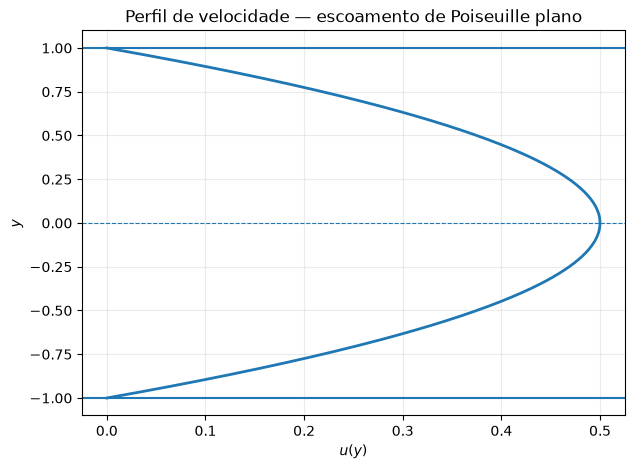

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros
h = 1.0
mu = 1.0
G = 1.0

# Pontos no domínio
y = np.linspace(-h, h, 300)

# Solução analítica
u = G / (2 * mu) * (h**2 - y**2)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(u, y, linewidth=2)

# Paredes
ax.axhline(h, linewidth=1.5)
ax.axhline(-h, linewidth=1.5)

# Linha central
ax.axhline(0, linewidth=0.8, linestyle="--")

ax.set_xlabel(r"$u(y)$")
ax.set_ylabel(r"$y$")
ax.set_title("Perfil de velocidade — escoamento de Poiseuille plano")

ax.grid(alpha=0.25)

plt.show()

### 6.4 Experimento computacional

A solução

$$
u(y)
=
\frac{G}{2\mu}(h^2-y^2)
$$

permite realizar experimentos sem modificar a estrutura do modelo.

Experimente alterar separadamente:

- a viscosidade $\mu$;
- o gradiente de pressão representado por $G$;
- a meia-altura $h$.

Antes de executar novamente o código, tente prever:

1. O que acontecerá com $u_{\max}$ se dobrarmos $\mu$?
2. O que acontecerá se dobrarmos $G$?
3. O que acontecerá se dobrarmos $h$?
4. O formato parabólico do perfil será alterado?

## 7. Solução manufaturada

Em muitos problemas numéricos, é útil construir um problema cuja solução
exata seja conhecida.

Essa estratégia é chamada de **solução manufaturada**.

Em vez de começar pela equação e procurar a solução, fazemos o caminho inverso:

1. escolhemos uma função $u(x)$;
2. substituímos essa função na equação diferencial;
3. determinamos o termo-fonte $f(x)$ correspondente.

Considere a equação de Poisson

$$
-u''(x)=f(x),
\qquad 0<x<1.
$$

Escolhemos

$$
u(x)=x(1-x).
$$

Como

$$
u''(x)=-2,
$$

temos

$$
f(x)=2.
$$

Além disso,

$$
u(0)=u(1)=0.
$$

Portanto, construímos o problema

$$
\boxed{
-u''(x)=2,
\qquad 0<x<1,
}
$$

com

$$
\boxed{
u(0)=u(1)=0.
}
$$

In [10]:
import sympy as sp

x = sp.symbols("x", real=True)

u = x * (1 - x)

f = -sp.diff(u, x, 2)

u, sp.simplify(f)

(x*(1 - x), 2)

In [11]:
u0 = sp.simplify(u.subs(x, 0))
u1 = sp.simplify(u.subs(x, 1))

u0, u1

(0, 0)

### Para pensar

1. Por que essa solução foi conveniente para impor condições de contorno homogêneas?
2. Se escolhermos uma função cúbica para $u(x)$, o termo-fonte $f(x)$ continuará constante?
3. Como essa estratégia poderá ser útil para testar uma solução obtida numericamente?

> **Observe**
>
> A solução manufaturada
>
> $$
> u(x)=x(1-x)
> $$
>
> possui a mesma estrutura parabólica encontrada no perfil de Poiseuille.
>
> Na próxima aula utilizaremos um problema desse tipo para comparar uma
> solução conhecida com uma aproximação obtida pelo Método dos Elementos
> Finitos.

## Exercício para a próxima aula — Preparando o ambiente FEniCSx

Na próxima aula iniciaremos a solução computacional de problemas de valor
de contorno utilizando o **FEniCSx**.

Antes da aula, cada aluno deverá preparar seu ambiente computacional.

### 1. Instalação

Instale o FEniCSx seguindo uma das alternativas apresentadas nas referências
abaixo.

> **Importante:** não é necessário compreender ainda todos os componentes
> do FEniCSx. Neste momento, nosso objetivo é apenas preparar e testar o
> ambiente computacional.

### 2. Teste da instalação

Depois da instalação, abra um notebook Jupyter e execute:

```python
import dolfinx

print("FEniCSx instalado com sucesso!")
print("Versão do DOLFINx:", dolfinx.__version__)

Execute também

### 2. Teste da instalação

Depois da instalação, abra um notebook Jupyter e execute:

```python
import dolfinx

print("FEniCSx instalado com sucesso!")
print("Versão do DOLFINx:", dolfinx.__version__)

### Para pensar

O comando

`mesh.create_unit_interval(MPI.COMM_WORLD, 8)`

cria uma discretização do intervalo

$$
[0,1].
$$

Antes da próxima aula, tente responder:

1. O que você imagina que representa o número `8`?
2. Quantos elementos foram criados?
3. Quantos vértices existem nessa malha?
4. O que deverá acontecer se substituirmos `8` por `16`?
5. O tamanho de cada elemento aumentará ou diminuirá quando passarmos de `8` para `16`?

> **Não é necessário conhecer o Método dos Elementos Finitos para responder.**
>
> Explore o comando, observe os resultados e formule suas hipóteses.


### Referências e material para consulta

1. **DOKKEN, J. S. — The FEniCSx Tutorial**

   Tutorial introdutório de FEniCSx, com exemplos em Python e notebooks
   interativos.

   [The FEniCSx Tutorial — Jørgen S. Dokken](https://jsdokken.com/dolfinx-tutorial/index.html)

2. **FEniCS Project — FEniCSx Documentation**

   Documentação oficial do DOLFINx, UFL, Basix e FFCx.

   [Documentação oficial do FEniCSx](https://docs.fenicsproject.org/)